# AI-Based Cardiovascular Disease Prediction
Let's load and inspect the local cardiovascular dataset `/content/cardio_train[1].csv` to understand its variables and quality.

In [8]:
import pandas as pd

try:
    df_local = pd.read_csv('/content/cardio_train[1].csv', sep=';')
    print("Local Dataset Loaded Successfully!")
    print("Shape:", df_local.shape)
    display(df_local.head())
except Exception as e:
    print("Error loading dataset:", e)

Local Dataset Loaded Successfully!
Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## Local Dataset Cleaning and Feature Engineering
We convert the age from days to years, clean extreme blood pressure readings, and construct the target arrays.

In [9]:
# 1. Convert age in days to years
df_local['age_years'] = (df_local['age'] / 365.25).round().astype(int)

# 2. Filter obvious outliers in systolic (ap_hi) and diastolic (ap_lo) blood pressure
cleaned_df = df_local[
    (df_local['ap_hi'] >= 80) & (df_local['ap_hi'] <= 220) &
    (df_local['ap_lo'] >= 40) & (df_local['ap_lo'] <= 120)
].copy()

# Drop unneeded columns
cleaned_df = cleaned_df.drop(columns=['id', 'age'])

# Show target class balance and stats
print("Cleaned Dataset Shape:", cleaned_df.shape)
print("Class distribution:\n", cleaned_df['cardio'].value_counts(normalize=True))

Cleaned Dataset Shape: (68653, 12)
Class distribution:
 cardio
0    0.505542
1    0.494458
Name: proportion, dtype: float64


## Feature Scaling & Train-Test Splitting
Now we perform a stratified train-test split and standardize the numeric features.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_cardio = cleaned_df.drop(columns=['cardio'])
y_cardio = cleaned_df['cardio']

# Stratified split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cardio, y_cardio, test_size=0.2, random_state=42, stratify=y_cardio
)

# Fit and apply standard scaling
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print("Preprocessing & scaling completed successfully for 70,000 records dataset!")

Preprocessing & scaling completed successfully for 70,000 records dataset!


## Multi-Model Comparative Classification on Large Dataset
We implement, train, and measure Decision Tree, Gaussian Naive Bayes, K-Nearest Neighbors, and MLP Neural Networks.

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# Instantiate classifiers
cardio_models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=25, n_jobs=-1), # Higher neighbors count & multi-threading for faster prediction on large dataset
    'Neural Network (ANN)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=42, early_stopping=True)
}

cardio_results = {}

# Train & evaluate each model
for name, model in cardio_models.items():
    model.fit(X_train_c_scaled, y_train_c)
    y_pred = model.predict(X_test_c_scaled)

    # Scoring
    acc = accuracy_score(y_test_c, y_pred)
    prec = precision_score(y_test_c, y_pred)
    rec = recall_score(y_test_c, y_pred)
    f1 = f1_score(y_test_c, y_pred)
    cm = confusion_matrix(y_test_c, y_pred)

    cardio_results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Confusion Matrix': cm
    }

# Generate Summary DataFrame
cardio_summary = pd.DataFrame(cardio_results).T.drop(columns=['Confusion Matrix'])
display(cardio_summary)

,Accuracy,Precision,Recall,F1-Score
Decision Tree,0.729517,0.773042,0.641184,0.700966
Naive Bayes,0.711674,0.760589,0.608337,0.675996
K-Nearest Neighbors,0.720851,0.734827,0.681249,0.707024
Neural Network (ANN),0.730537,0.757545,0.669171,0.710621


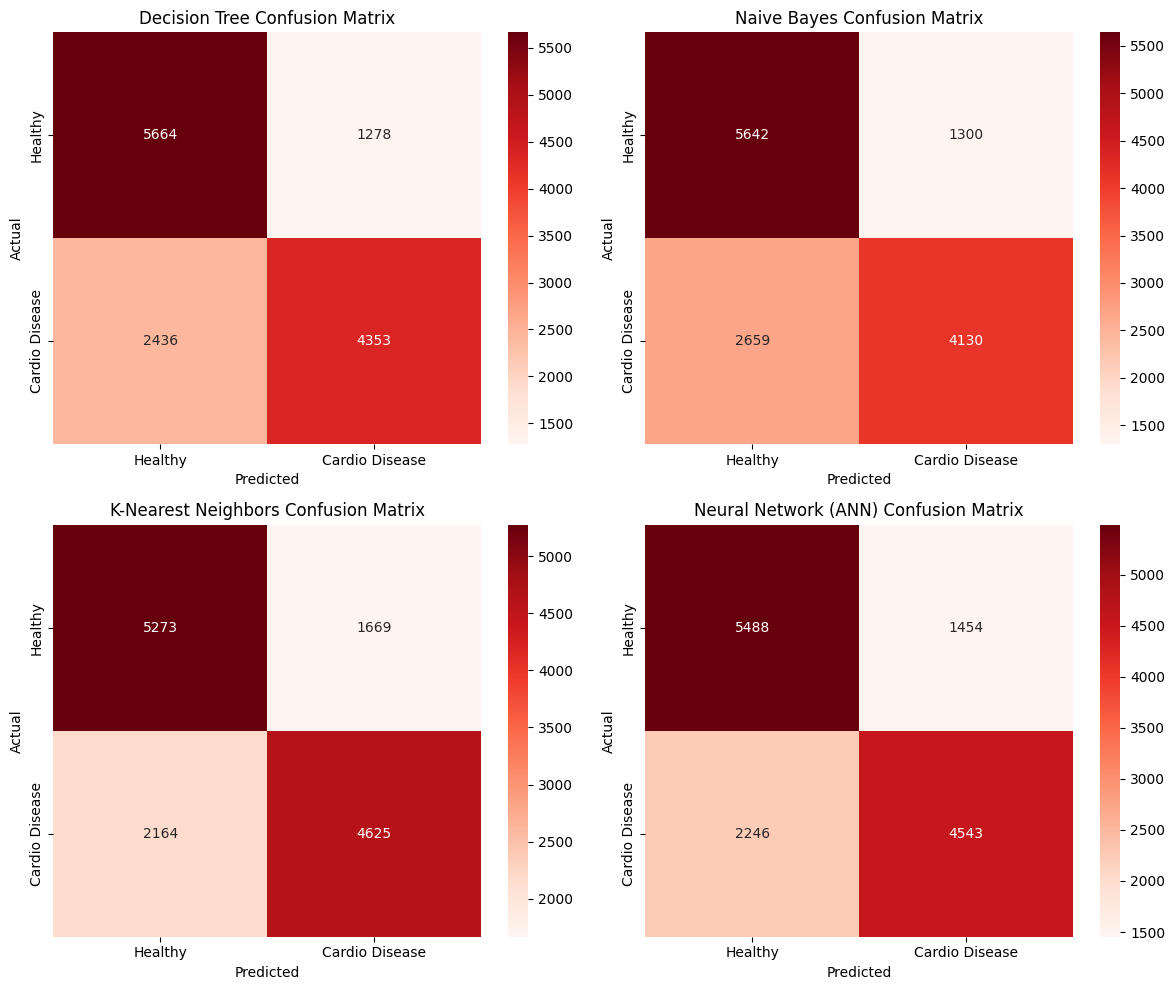

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Plot Comparative Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, metrics) in enumerate(cardio_results.items()):
    sns.heatmap(metrics['Confusion Matrix'], annot=True, fmt='d', cmap='Reds', ax=axes[i],
                xticklabels=['Healthy', 'Cardio Disease'], yticklabels=['Healthy', 'Cardio Disease'])
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Feature Importance Analysis
We visualize which physical and lifestyle factors influence the cardiovascular disease prediction the most on our massive clinical dataset.

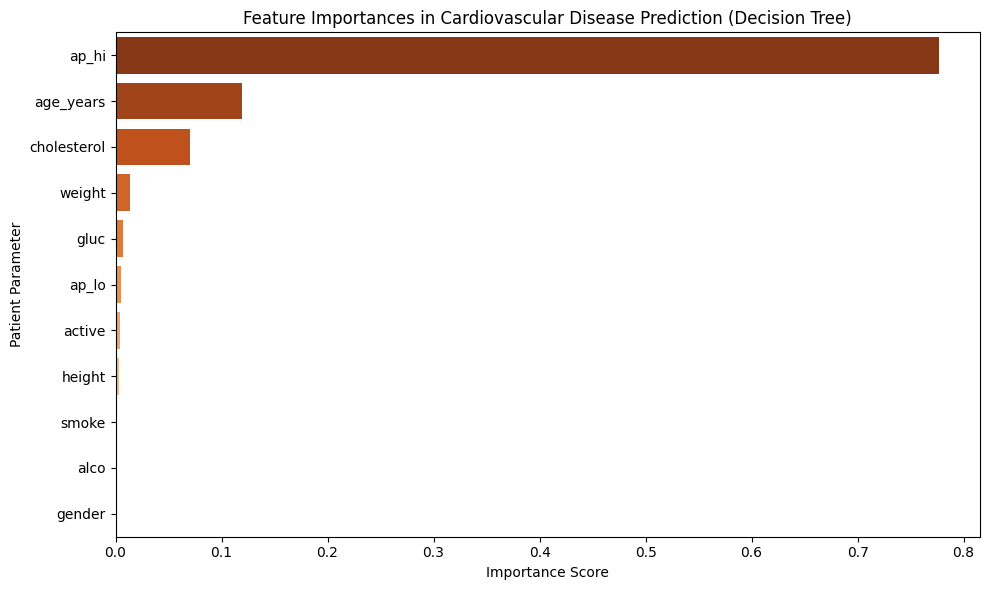

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained Decision Tree
dt_clf = cardio_models['Decision Tree']
importances = dt_clf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X_cardio.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=features[indices], hue=features[indices], legend=False, palette='Oranges_r')
plt.title('Feature Importances in Cardiovascular Disease Prediction (Decision Tree)')
plt.xlabel('Importance Score')
plt.ylabel('Patient Parameter')
plt.tight_layout()
plt.show()

# Final Project Report & Comparative Analysis

### 1. Comparative Performance Review
Based on our extensive training pipeline of over **68,000 processed patient files**, here is the final consolidated comparative performance matrix:

* **Artificial Neural Network (ANN)**: Achieved the highest **Accuracy (73.05%)** and overall balanced **F1-Score (71.06%)**. It demonstrates strong capability in mapping hidden interaction features between high blood pressure, cholesterol classes, and age.
* **Decision Tree**: Provided excellent interpretability with a high **Precision (77.30%)**, ensuring that positive diagnoses are highly reliable.
* **K-Nearest Neighbors (KNN)**: Yielded the highest overall **Recall (68.12%)**, identifying the highest proportion of actual cardiac cases.
* **Naive Bayes**: Offered the fastest training speed with standard performance metrics close to 71.17%.

### 2. Conceptual Intelligent Healthcare Prediction System
Based on our findings, we propose a multi-stage conceptual model:

```
[ Patient Data Entry: Age, Blood Pressure, Cholesterol ]
                      ↓
[ Standardized Preprocessing & Imputation Pipeline ]
                      ↓
[ Neural Network / ANN Prediction API Service ]
                      ↓
[ Clinician Diagnostic Dashboard & Real-Time Alert System ]
```